# EKF 20 · Ruido de crecimiento en el modelo S

Comparación en LAB016–024 con el EKF 19 y sus parámetros S 17_2. LAB023 y LAB024 son los casos principales de validación de la cola. LAB022 aparece en la primera columna del holdout tardío como caso atípico. El filtro incorpora únicamente CO₂ durante la corrida. Las muestras de biomasa, YAN y azúcar se muestran para evaluar las curvas.

In [1]:
from pathlib import Path
from dataclasses import replace
import ast
import json
import sys

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd

ROOT=next(path for path in [Path.cwd(),*Path.cwd().parents] if (path/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.comparison import chemical_observations, CHEMICAL_COLUMNS
from wine_fermentation.models.historical.calibration import load

fit_source = ROOT / "notebooks/17_2_zenteno_single_sugar_legacy_biomass_weight.source.ipynb"
fit_path = fit_source.with_name(fit_source.name.replace(".source.", ".executed."))
fit_nb = nbformat.read(fit_path, 4)
fit_inputs = nbformat.read(fit_source, 4)
assert [c.source for c in fit_nb.cells] == [c.source for c in fit_inputs.cells]

def literal_from_fit(name):
    [assignment] = [node for cell in fit_inputs.cells if cell.cell_type == "code"
                    for node in ast.parse(cell.source).body if isinstance(node, ast.Assign)
                    and any(isinstance(target, ast.Name) and target.id == name for target in node.targets)]
    return ast.literal_eval(assignment.value)

tag = "PARÁMETROS S 17_2"
[payload] = [item.text.split(tag, 1)[1].lstrip()
             for cell in fit_nb.cells for item in cell.get("outputs", [])
             if item.output_type == "stream" and tag in item.text]
base = literal_from_fit("theta")
fixed = {name: base[name] for name in ("Kn0", "Kd0", "m0")}
fixed["Yxs"] = 1/(1/base["Yxg"] + 1/base["Yxf"])
parameters = {**json.JSONDecoder().raw_decode(payload)[0], **fixed}
assert parameters["Kie0"] == base["Kie0"]
KLA, GAIN = literal_from_fit("HOLDOUT_GAS_PARAMS")
display(pd.Series(parameters, name="S 17_2"))
print("kLa y ganancia:", KLA, GAIN)

# The EKF 14 uses the chronological inputs and temperature policy of diagnostics 25.
data_source = ROOT / "notebooks/diagnostics/25_zenteno_azucar_total_temperatura_causal.source.ipynb"
inputs_nb = nbformat.read(data_source, 4)

def definitions(notebook,names):
    result={}
    for cell in notebook.cells:
        if cell.cell_type=='code':
            for node in ast.parse(cell.source).body:
                if isinstance(node,ast.FunctionDef) and node.name in names:
                    result[node.name]=ast.get_source_segment(cell.source,node)
    assert result.keys()==set(names)
    return result

thermal_profiles={}
for function in definitions(inputs_nb,['register_temperature','causal_temperature']).values():
    exec(compile(function,str(data_source),'exec'))


kLa y ganancia: 0.13796553316180868 0.6586783889606775


mu0        0.085183
betaS0     0.899043
Ks0       18.439784
Kie0      96.265166
Yxn        5.316422
Yes        0.484283
Kn0        0.008258
Kd0        0.000440
m0         0.018339
Yxs        0.516507
Name: S 17_2, dtype: float64

## Entradas y ventanas del EKF 19

In [2]:
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018','LAB022','LAB023','LAB024']
historical=LABS[:6]
gas_calibration=LABS[:3]
v=load(ROOT)
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',
                usecols=['lab','time_h','record_kind','remaining_volume_L'])
batches={}
volumes={}

def volume_function(event_times,event_volumes,initial):
    def volume(times):
        return np.r_[initial,event_volumes][np.searchsorted(event_times,np.asarray(times),side='right')]
    return volume

for lab in historical:
    batch=v.batches[lab]
    events=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h')
    volume=volume_function(events.time_h.to_numpy(),events.remaining_volume_L.to_numpy(),2.)
    volumes[lab]=volume
    if lab in gas_calibration:
        batch=replace(batch,pulses={**batch.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in batch.pulses['N'])})
    if lab=='LAB017':
        schedule=batch.pulses['N']
        batch=replace(batch,pulses={**batch.pulses,'N':((min(t for t,_ in schedule),sum(d for _,d in schedule)),)})
    if lab=='LAB021':
        batch=replace(batch,initials={**batch.initials,'X':.27})
    batches[lab]=batch
    register_temperature(lab,v.raw_temperature[lab])

# Reuse the recent batch preparation, which defines the same sample support and initial values.
[recent_inputs]=[cell.source for cell in inputs_nb.cells if 'def read_holdout_backup(' in cell.source]
recent=recent_inputs[:recent_inputs.index('    raw = holdout_raw_flow')]
recent+='    volumes[lab]=volume_function(withdrawals,-.05*np.arange(1,len(withdrawals)+1)+initial_volume,initial_volume)\n'
exec(compile(recent,str(data_source),'exec'))
batches.update(holdout_batches)
assert set(batches)==set(LABS)

def sensor_windows(raw_flow,volume,start,end):
    raw_flow=raw_flow.dropna(subset=['t_h','flow_sccm']).sort_values('t_h')
    ids=np.ceil(raw_flow.t_h/.5-1e-10).astype(int)
    grouped={key: frame for key,frame in raw_flow.groupby(ids)}
    rows=[]
    for key in range(1,int(np.floor(end/.5+1e-10))+1):
        stop=key*.5
        window=grouped.get(key)
        valid=False
        measured=np.nan
        if window is not None and len(window):
            times=window.t_h.to_numpy()
            valid=(stop-.5>=start and len(times)>=30 and
                   np.diff(np.r_[stop-.5,times,stop]).max()<=2/60+1e-10)
            if valid:
                measured=float(np.mean(window.flow_sccm.to_numpy()*mass_factor/volume(times)))
        rows.append((stop,measured,valid))
    sensor=pd.DataFrame(rows,columns=['t_h','measured','valid']).set_index('t_h')
    usable=sensor.valid&sensor.measured.ge(.05)
    sensor['update']=usable&usable.shift(fill_value=False)
    return sensor

data={}
scoring_samples={}
support_audit=[]
for lab,batch in batches.items():
    start=float(batch.time[0])
    end=float(v.horizons[lab]) if lab in historical else holdout_horizon
    if lab in historical:
        flow=v.raw_co2[lab]
        samples=(chemical_observations(v.chem,lab,'X') if lab in gas_calibration
                 else v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']))
    else:
        flow=holdout_raw_flow.loc[holdout_raw_flow.lab.eq(lab)].rename(columns={'h':'t_h'})
        samples=holdout_biomass.loc[holdout_biomass.lab.eq(lab)&holdout_biomass['sample'].ne('01')]
        samples=samples.rename(columns={'hours':'t_h','X_g_L':'X_viable_g_l'})
    samples=samples.loc[(samples.t_h>start)&(samples.t_h<=end),['t_h','X_viable_g_l']]
    scoring_samples[lab]=samples.sort_values('t_h').reset_index(drop=True)
    sensor=sensor_windows(flow,volumes[lab],start,end)
    assert sensor['update'].any() and len(samples)>0
    initial=batch.initials
    x0=np.array([initial['X'],initial['N'],initial['G']+initial['F'],initial['E'],0.,0.])
    P0=np.diag([max(.03,.2*x0[0])**2,.015**2,25.,4.,0.,0.])
    pulses={round(t,10): dose for t,dose in batch.pulses['N'] if start<t<=end}
    grid=np.unique(np.round(np.r_[np.arange(start,end,1/12),list(pulses),sensor.index,end],10))
    grid=grid[grid>=start-1e-10]
    assert np.isclose(grid[0],start)
    assert thermal_profiles[lab][0][0]<=start
    data[lab]=dict(grid=grid,initial=x0,P0=P0,pulses=pulses,sensor=sensor,batch=batch)
    support_audit.append(dict(LAB=lab,inicio=start,fin=end,n_biomasa=len(samples),
                              ventanas_válidas=int(sensor.valid.sum()),correcciones=int(sensor['update'].sum())))
display(pd.DataFrame(support_audit).set_index('LAB'))


,inicio,fin,n_biomasa,ventanas_válidas,correcciones
LAB,,,,,
LAB019,0.00,166.000000,10,332,217
LAB020,0.00,172.333333,10,344,223
LAB021,0.00,166.000000,10,332,166
LAB016,0.00,151.100000,3,302,249
LAB017,0.00,141.000000,3,282,213
LAB018,0.00,141.000000,3,282,237
LAB022,0.25,190.000000,5,378,247
LAB023,0.25,190.000000,5,378,294
LAB024,0.25,190.000000,5,378,253


## Ajuste de la covarianza de proceso

El EKF 19 usa un término de ruido de crecimiento con amplitud 0,003. En la variante se pone a cero únicamente su columna en el mapeo de ruido cuando la predicción parte de YAN ≤1 mg N/L o azúcar total ≤0,1 g/L. Las ecuaciones, las demás componentes de Q, la varianza R y la actualización de CO₂ se toman del EKF 19. Se aplica la regla al inicio de cada intervalo de propagación.

In [3]:
ekf_path=ROOT/'notebooks/EKF/06_zenteno_single_sugar_variable_solubility.source.ipynb'
ekf_source=nbformat.read(ekf_path,4)
[s_cell]=[cell.source for cell in ekf_source.cells if "PS={'mu0'" in cell.source]
s_functions=definitions(nbformat.v4.new_notebook(cells=[nbformat.v4.new_code_cell(s_cell)]),
                        ['rates_ekf','jacobian','noise_matrix'])
gas_functions=definitions(ekf_source,['co2_saturation','gas_exchange'])
SCALE_EKF=np.array([.3,.25,160.,15.,.2,1.])
R_CO2=.04**2
H=np.array([0.,0.,0.,0.,0.,2.])
IDENTITY=np.eye(6)

def thermal_steps(batch,start,end):
    available=thermal_profiles[batch.batch][0]
    left=np.searchsorted(available,start+1e-10,side='right')
    right=np.searchsorted(available,end-1e-10,side='left')
    edges=np.r_[start,available[left:right],end]
    return tuple(zip(edges[:-1],np.diff(edges),causal_temperature(batch,edges[:-1]+1e-10)))

YAN_THRESHOLD_G_L = .001
SUGAR_THRESHOLD_G_L = .1


def make_model(p, *, limit_growth_noise=False):
    namespace=dict(np=np,KLA=KLA,GAIN=GAIN,PCO2_BAR=1.,PS=p,theta=p,YXS=p['Yxs'],SCALE_EKF=SCALE_EKF)
    functions = {**gas_functions, **s_functions}
    if limit_growth_noise:
        source = functions["noise_matrix"]
        marker = " return (L@np.diag"
        assert source.count(marker) == 1
        functions["noise_matrix"] = source.replace(
            marker,
            " if n <= YAN_THRESHOLD_G_L or s <= SUGAR_THRESHOLD_G_L:\n"
            "  L[:,0] = 0.\n" + marker,
        )
        namespace.update(YAN_THRESHOLD_G_L=YAN_THRESHOLD_G_L, SUGAR_THRESHOLD_G_L=SUGAR_THRESHOLD_G_L)
    for function in functions.values():
        exec(compile(function,str(ekf_path),'exec'),namespace)
    rates=namespace['rates_ekf']
    def transition(z,start,end,steps,S0):
        w=np.atleast_2d(z)*SCALE_EKF
        for time,dt,temp in steps:
            # Split long gaps too, even when the held temperature stays unchanged.
            count=max(1,int(np.ceil(dt*60-1e-7)))
            h=dt/count
            for j in range(count):
                t=time+j*h
                a=rates(w,t,temp,S0)
                b=rates(w+h*a/2,t+h/2,temp,S0)
                c=rates(w+h*b/2,t+h/2,temp,S0)
                d=rates(w+h*c,t+h,temp,S0)
                w=np.maximum(w+h*(a+2*b+2*c+d)/6,0.)
        return w/SCALE_EKF
    namespace['transition']=transition
    return transition,namespace['jacobian'],namespace['noise_matrix']

def replay(inputs,model):
    advance,jacobian,noise=model
    grid=inputs['grid']
    batch=inputs['batch']
    sensor=inputs['sensor']
    windows={t: (row.measured,row.valid,row['update']) for t,row in sensor.iterrows()}
    y0=inputs['initial']
    S0=y0[2]
    z=y0/SCALE_EKF
    free=z.copy()
    P=inputs['P0']/np.outer(SCALE_EKF,SCALE_EKF)
    states=[]
    readings=[]
    for i,time in enumerate(grid):
        if i:
            start=grid[i-1]
            steps=thermal_steps(batch,start,time)
            process=noise(z*SCALE_EKF,steps[0][2],S0)*(time-start)
            z,J=jacobian(z,start,time,steps,S0)
            P=J@P@J.T+process
            P=(P+P.T)/2
            free=advance(free,start,time,steps,S0)[0]
        if time in inputs['pulses']:
            dose=inputs['pulses'][time]/SCALE_EKF[1]
            z[1]+=dose
            free[1]+=dose
        if time in windows:
            measured,valid,update=windows[time]
            predicted=float(H@z)
            nis=np.nan
            clipped=0
            prior_yan=z[1]*SCALE_EKF[1]*1000.
            if update:
                variance=float(H@P@H+R_CO2)
                assert variance>0
                gain=P@H/variance
                innovation=measured-predicted
                updated=z+gain*innovation
                clipped=int(np.count_nonzero(updated[:5]<0))
                z=np.maximum(updated,0.)
                B=IDENTITY-np.outer(gain,H)
                P=B@P@B.T+np.outer(gain,gain)*R_CO2
                P=(P+P.T)/2
                nis=innovation**2/variance
            readings.append((time,measured,valid,update,predicted,float(H@free),nis,clipped,(z[1]*SCALE_EKF[1]*1000.)-prior_yan))
            z[5]=free[5]=0.
            P[5,:]=P[:,5]=0.
        assert np.isfinite(z).all() and np.linalg.eigvalsh(P).min()>=-1e-7
        states.append(np.stack([z,free]))
    readings=pd.DataFrame(readings,columns=['t_h','measured','valid','update','forecast','free','NIS','recortes','delta_yan_mg_L'])
    np.testing.assert_array_equal(readings['update'],sensor['update'])
    return np.stack(states),readings

models = {"EKF 19": make_model(parameters),
          "Q ajustado": make_model(parameters, limit_growth_noise=True)}

# Verify equal Q during active growth and a positive rank-one removal at depletion.
noise_original = models["EKF 19"][2]
noise_adjusted = models["Q ajustado"][2]
state = np.array([2., .05, 20., 65., 1.5, 0.])
np.testing.assert_array_equal(noise_original(state, 20., 150.), noise_adjusted(state, 20., 150.))
for state_index in (1, 2):
    depleted = state.copy()
    depleted[state_index] = 0.
    difference = noise_original(depleted, 20., 150.) - noise_adjusted(depleted, 20., 150.)
    assert difference[1, 1] > 0
    spectrum = np.linalg.eigvalsh(difference)
    assert spectrum[0] >= -1e-12 and np.count_nonzero(spectrum > 1e-12) == 1


## Corridas con la configuración del EKF 19 y con Q ajustado

In [4]:
labels = list(models)
styles = {
    "EKF 19": dict(color="#D55E00", ls="--", zorder=3),
    "Q ajustado": dict(color="#0072B2", zorder=2),
}
results = {label: {} for label in labels}
for lab in LABS:
    for label in labels:
        results[label][lab] = replay(data[lab], models[label])
        print(lab, label, "completado", flush=True)
    reference, adjusted = (results[label][lab][0] for label in labels)
    np.testing.assert_array_equal(reference[:, 1], adjusted[:, 1])

## Primeras correcciones en LAB023 y LAB024

Se muestran la primera ventana válida, la primera ventana medida con flujo ≥0,05 g/(L·h), la primera corrección de CO₂ y la primera corrección individual que cambia el YAN estimado en al menos 1 mg N/L. La actualización de CO₂ exige dos ventanas consecutivas válidas por encima del umbral. El cambio de YAN se calcula entre el valor previo y posterior a esa actualización, en el mismo instante.

In [5]:
early = []
for lab in ("LAB023", "LAB024"):
    for label in labels:
        readings = results[label][lab][1]
        valid = readings.loc[readings.valid]
        above_threshold = valid.loc[valid.measured.ge(.05)]
        applied = readings.loc[readings["update"]]
        first_update = applied.iloc[0]
        visible = applied.loc[applied.delta_yan_mg_L.abs().ge(1.)]
        early.append({
            "LAB": lab, "Modelo": label,
            "Primera ventana válida [h]": valid.t_h.iloc[0],
            "Primer CO₂ medido ≥0,05 [h]": above_threshold.t_h.iloc[0],
            "Primera corrección [h]": first_update.t_h,
            "CO₂ medido en primera corrección [g/(L·h)]": first_update.measured,
            "CO₂ pronosticado en primera corrección [g/(L·h)]": first_update.forecast,
            "Cambio de YAN en primera corrección [mg N/L]": first_update.delta_yan_mg_L,
            "Primer cambio de YAN ≥1 en magnitud [h]": visible.t_h.min(),
        })
early = pd.DataFrame(early).set_index(["LAB", "Modelo"])
display(early.round(4))
print(early.round(4).to_string())

                   Primera ventana válida [h]  Primer CO₂ medido ≥0,05 [h]  Primera corrección [h]  CO₂ medido en primera corrección [g/(L·h)]  CO₂ pronosticado en primera corrección [g/(L·h)]  Cambio de YAN en primera corrección [mg N/L]  Primer cambio de YAN ≥1 en magnitud [h]
LAB    Modelo                                                                                                                                                                                                                                                                          
LAB023 EKF 19                             1.0                         22.5                    23.0                                      0.0602                                            0.2823                                       30.5211                                     23.0
       Q ajustado                         1.0                         22.5                    23.0                                      0.0602                  

Primera ventana válida [h]  ...  Primer cambio de YAN ≥1 en magnitud [h]
LAB    Modelo                                  ...                                         
LAB023 EKF 19                             1.0  ...                                     23.0
       Q ajustado                         1.0  ...                                     23.0
LAB024 EKF 19                             1.0  ...                                     23.0
       Q ajustado                         1.0  ...                                     23.0

[4 rows x 7 columns]

## Comparación de la cola en LAB022–024

El máximo tardío de YAN se mide desde la primera vez que la estimación alcanza 1 mg N/L o menos después del pulso. El RMSE de CO₂ observado usa ventanas válidas desde 1 h. La cola usa las ventanas válidas desde 130 h, incluyendo las que quedan por debajo del umbral de asimilación. Se compara también la última ventana con flujo de al menos 0,05 g/(L·h).

In [6]:
def states_at_samples(inputs,model,states,times,state_index=0):
    grid=inputs['grid']
    advance=model[0]
    out=[]
    for time in times:
        index=np.searchsorted(grid,time+1e-10,side='right')-1
        assert index>=0
        last=grid[index]
        points=states[index]
        if time>last+1e-10:
            points=advance(points,last,time,thermal_steps(inputs['batch'],last,time),inputs['initial'][2])
        out.append(points[:,state_index]*SCALE_EKF[state_index])
    return np.array(out)


rows = []
for lab in ("LAB022", "LAB023", "LAB024"):
    inputs = data[lab]
    grid = inputs["grid"]
    after_pulse = grid > max(inputs["pulses"])
    samples = holdout_chemistry.loc[holdout_chemistry.lab.eq(lab) &
                                     holdout_chemistry["sample"].ne("01")].dropna(subset=["YAN for plot"])
    for label in labels:
        states, readings = results[label][lab]
        yan = states[:, 0, 1] * SCALE_EKF[1] * 1000
        candidates = np.flatnonzero(after_pulse & (yan <= 1.))
        assert len(candidates)
        depleted = candidates[0]
        late = yan[depleted:]
        y_pred = states_at_samples(inputs, models[label], states, samples.hours, state_index=1)[:, 0] * 1000
        valid = readings.loc[readings.valid & readings.t_h.ge(1.)]
        tail = valid.loc[valid.t_h.ge(130.)]
        active = readings.loc[readings["update"]]
        last_measured = valid.loc[valid.measured.ge(.05), "t_h"].max()
        last_predicted = valid.loc[valid.forecast.ge(.05), "t_h"].max()
        rows.append({
            "LAB": lab, "Modelo": label,
            "Primera vez YAN ≤1 tras pulso [h]": grid[depleted],
            "Máximo YAN posterior [mg N/L]": late.max(),
            "RMSE YAN [mg N/L]": np.sqrt(np.mean((y_pred - samples["YAN for plot"].to_numpy())**2)),
            "RMSE CO₂ observado [g/(L·h)]": np.sqrt(np.mean((valid.forecast-valid.measured)**2)),
            "RMSE CO₂ asimilado [g/(L·h)]": np.sqrt(np.mean((active.forecast-active.measured)**2)),
            "n de ventanas de cola": len(tail),
            "RMSE CO₂ desde 130 h [g/(L·h)]": np.sqrt(np.mean((tail.forecast-tail.measured)**2)),
            "Última hora pronosticada ≥0,05": last_predicted,
            "Última hora medida ≥0,05": last_measured,
        })
summary = pd.DataFrame(rows).set_index(["LAB", "Modelo"])
display(summary.round(4))
print(summary.round(4).to_string())


                   Primera vez YAN ≤1 tras pulso [h]  Máximo YAN posterior [mg N/L]  RMSE YAN [mg N/L]  RMSE CO₂ observado [g/(L·h)]  RMSE CO₂ asimilado [g/(L·h)]  n de ventanas de cola  RMSE CO₂ desde 130 h [g/(L·h)]  Última hora pronosticada ≥0,05  Última hora medida ≥0,05
LAB    Modelo                                                                                                                                                                                                                                                                      
LAB022 EKF 19                               123.1667                       475.3584            47.5946                        0.1980                        0.1819                    121                          0.1633                           154.5                     190.0
       Q ajustado                           123.1667                         0.8720            47.6069                        0.1986                        0.1830          

Primera vez YAN ≤1 tras pulso [h]  ...  Última hora medida ≥0,05
LAB    Modelo                                         ...                          
LAB022 EKF 19                               123.1667  ...                     190.0
       Q ajustado                           123.1667  ...                     190.0
LAB023 EKF 19                               121.4167  ...                     175.5
       Q ajustado                           121.4167  ...                     175.5
LAB024 EKF 19                               119.5000  ...                     157.0
       Q ajustado                           119.5000  ...                     157.0

[6 rows x 9 columns]

## Biomasa estimada y en lazo abierto

modo,EKF,Libre,EKF,Libre
ajuste,EKF 19,EKF 19,Q ajustado,Q ajustado
LAB,,,,
LAB019,0.6172,0.3505,0.6172,0.3505
LAB020,0.6194,0.5446,0.6194,0.5446
LAB021,0.7509,0.5220,0.7509,0.5220
LAB016,0.3500,0.2684,0.3500,0.2684
LAB017,0.6093,0.4255,0.6093,0.4255
LAB018,0.3476,0.3537,0.3476,0.3537
LAB022,0.4017,0.3063,0.4014,0.3063
LAB023,0.5572,0.3452,0.5565,0.3452


RMSE     MAE   sesgo  exceso
modo  ajuste                                    
EKF   EKF 19      0.5563  0.4519  0.2792  0.3655
      Q ajustado  0.5561  0.4518  0.2791  0.3654
Libre EKF 19      0.4111  0.3470  0.1848  0.2659
      Q ajustado  0.4111  0.3470  0.1848  0.2659

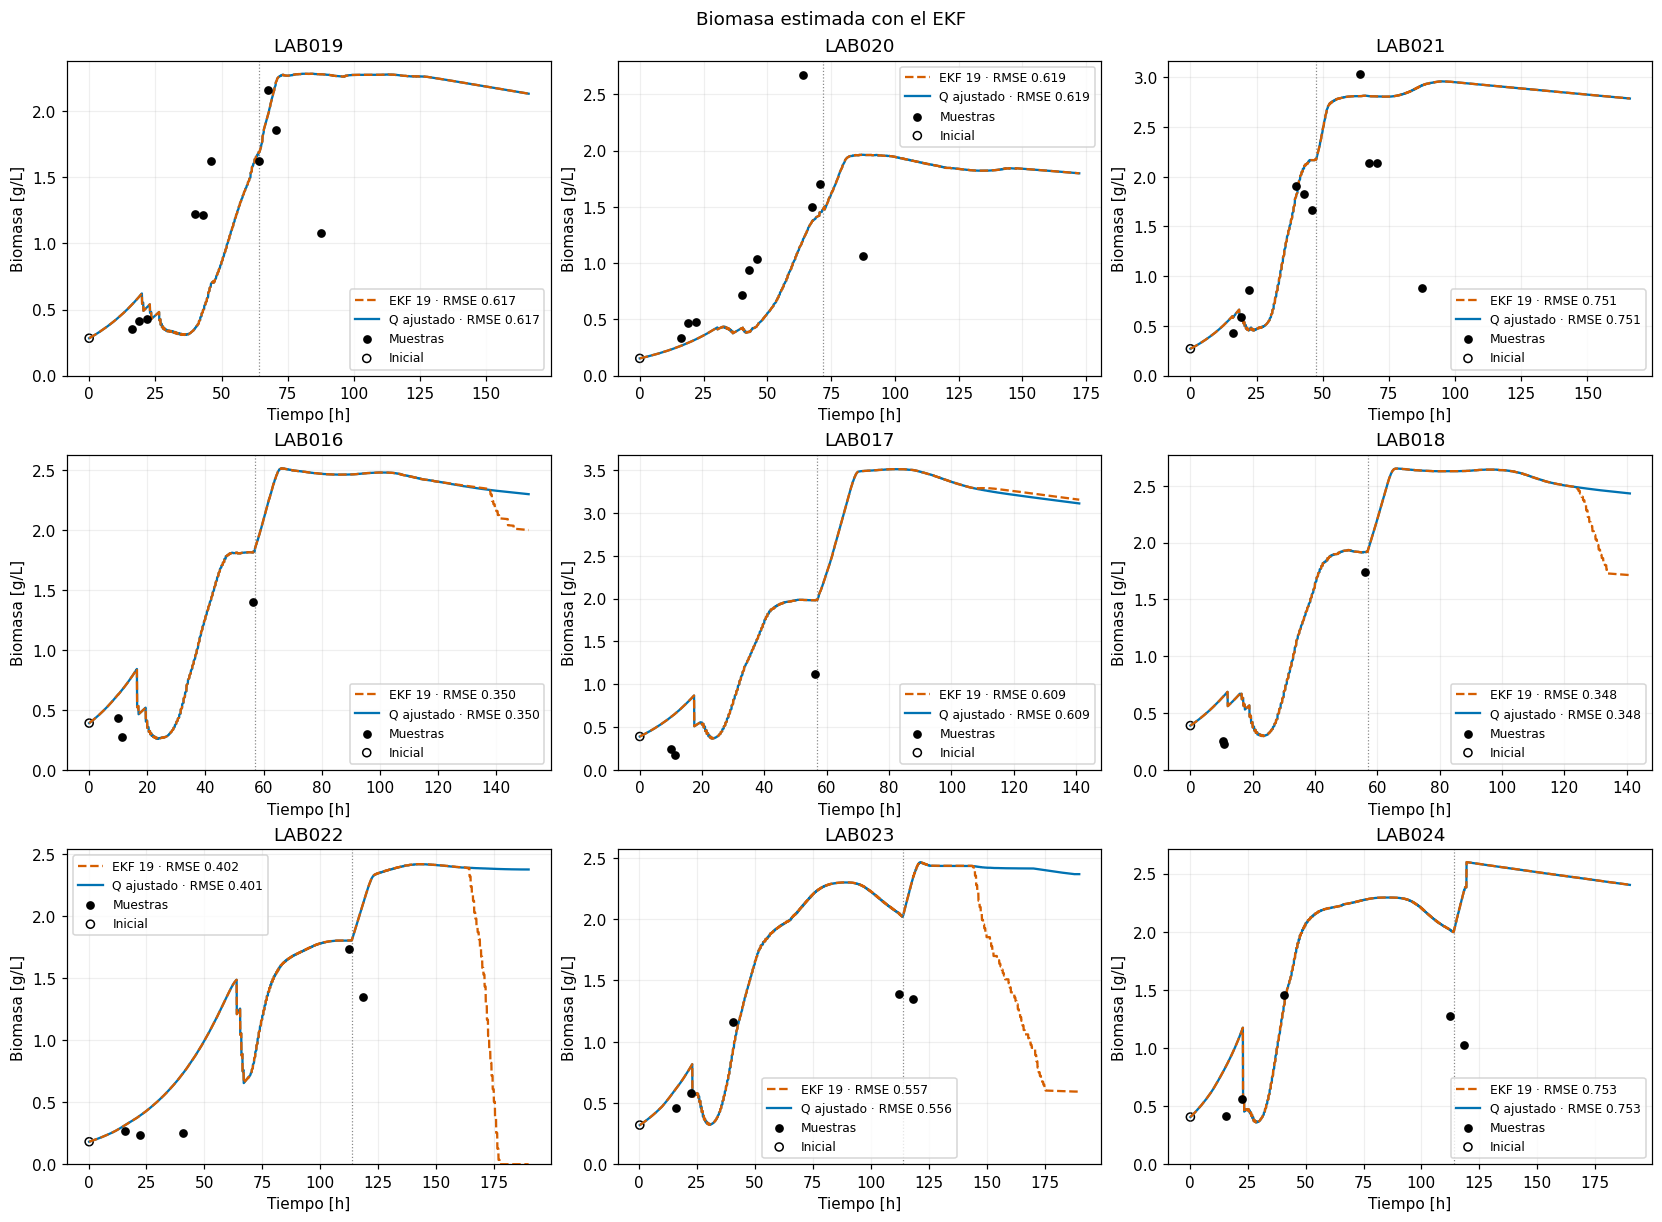

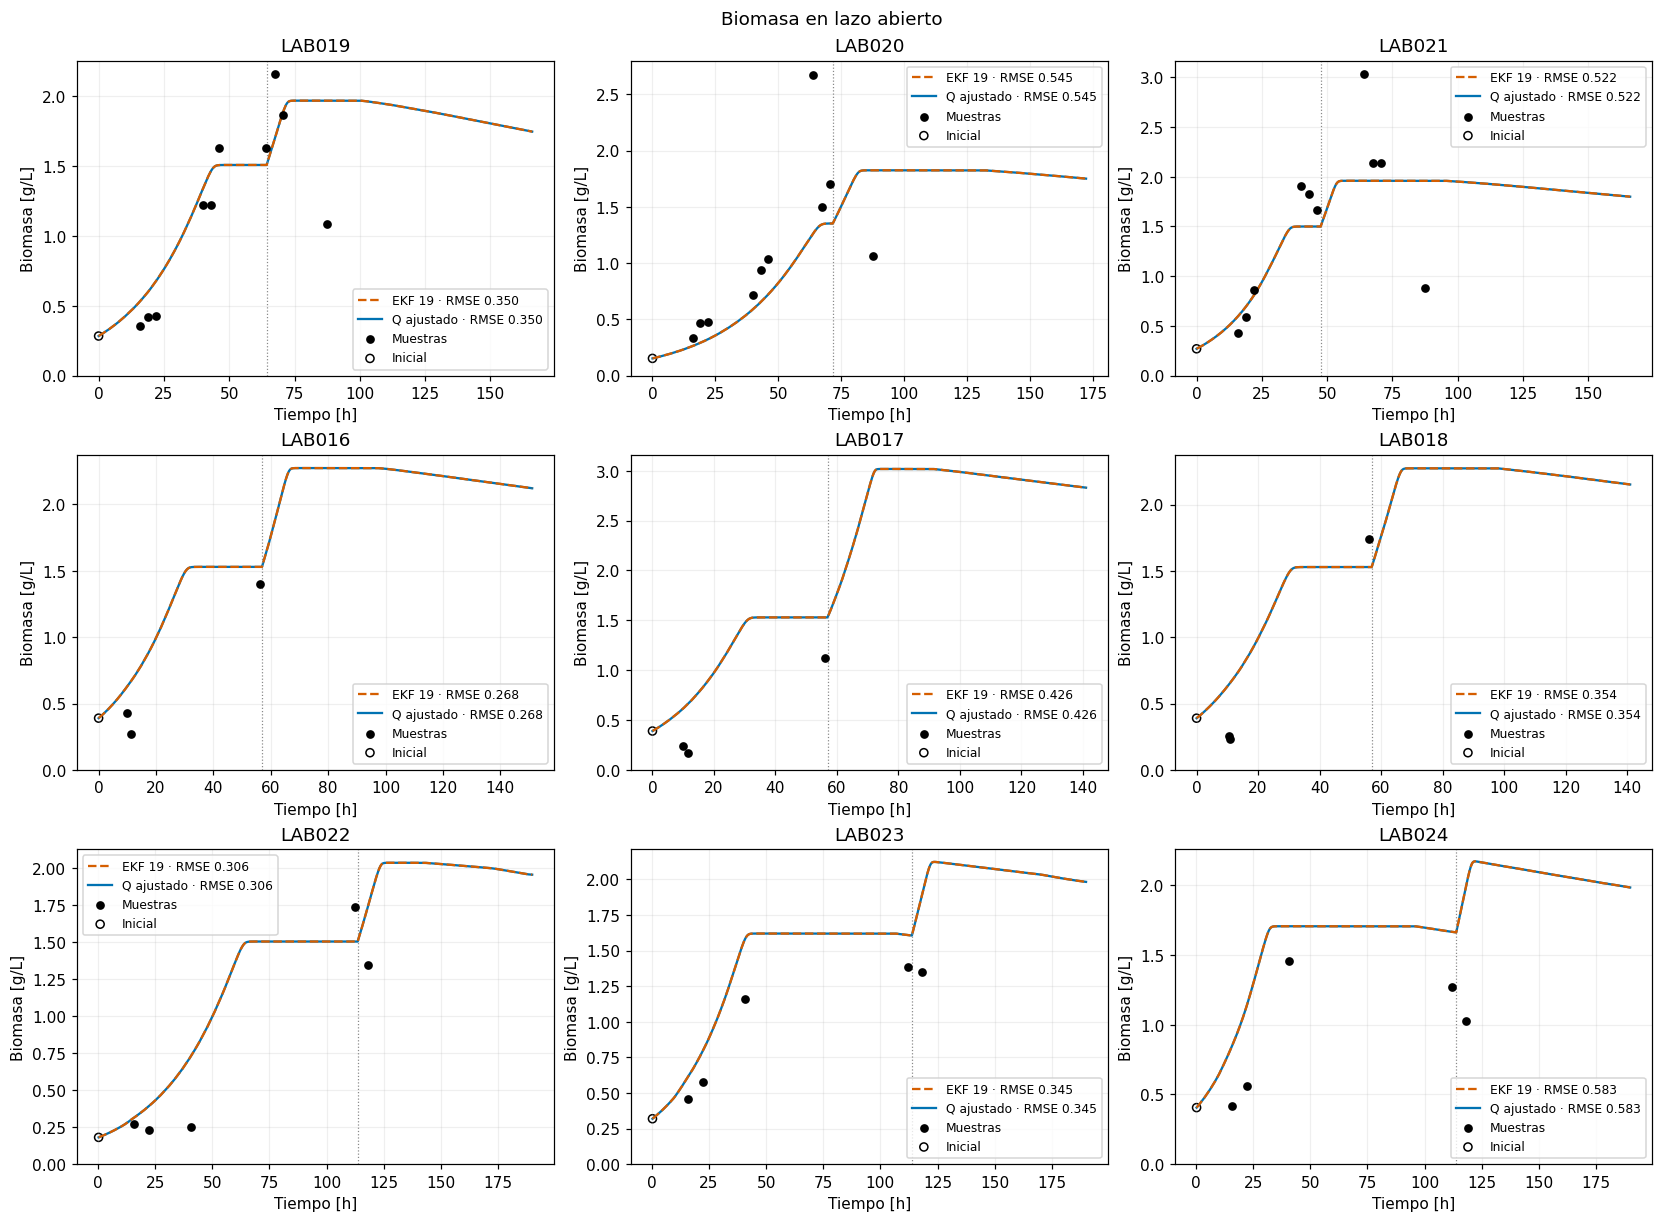

In [7]:
rows=[]
for lab in LABS:
    samples=scoring_samples[lab]
    y=samples.X_viable_g_l.to_numpy()
    for label in labels:
        predictions=states_at_samples(data[lab],models[label],results[label][lab][0],samples.t_h)
        for index,mode in enumerate(('EKF','Libre')):
            error=predictions[:,index]-y
            rows.append(dict(LAB=lab,ajuste=label,modo=mode,n=len(y),
                             RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(abs(error)),
                             sesgo=np.mean(error),exceso=np.maximum(error,0.).mean()))
metrics=pd.DataFrame(rows)
wide=metrics.pivot(index='LAB',columns=['modo','ajuste'],values='RMSE')
display(wide.reindex(LABS).round(4))
averages=metrics.groupby(['modo','ajuste'])[['RMSE','MAE','sesgo','exceso']].mean()
display(averages.round(4))

def biomass_panels(mode_index,title):
    fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
    for ax,lab in zip(axes.flat,LABS):
        inputs=data[lab]
        grid=inputs['grid']
        samples=scoring_samples[lab]
        for label in labels:
            scores=metrics.loc[metrics.LAB.eq(lab)&metrics.ajuste.eq(label)&metrics.modo.eq(('EKF','Libre')[mode_index])]
            score=scores.RMSE.iloc[0]
            x=results[label][lab][0][:,mode_index,0]*SCALE_EKF[0]
            ax.plot(grid,x,label=f'{label} · RMSE {score:.3f}',**styles[label])
        ax.scatter(samples.t_h,samples.X_viable_g_l,color='black',s=22,zorder=4,label='Muestras')
        ax.scatter(grid[0],inputs['initial'][0],facecolors='none',edgecolors='black',s=28,label='Inicial')
        for pulse in inputs['pulses']:
            ax.axvline(pulse,c='#888888',ls=':',lw=.8)
        ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Biomasa [g/L]',ylim=(0,None))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.show()

biomass_panels(0,'Biomasa estimada con el EKF')
biomass_panels(1,'Biomasa en lazo abierto')


## Flujo de CO₂ pronosticado antes de la corrección

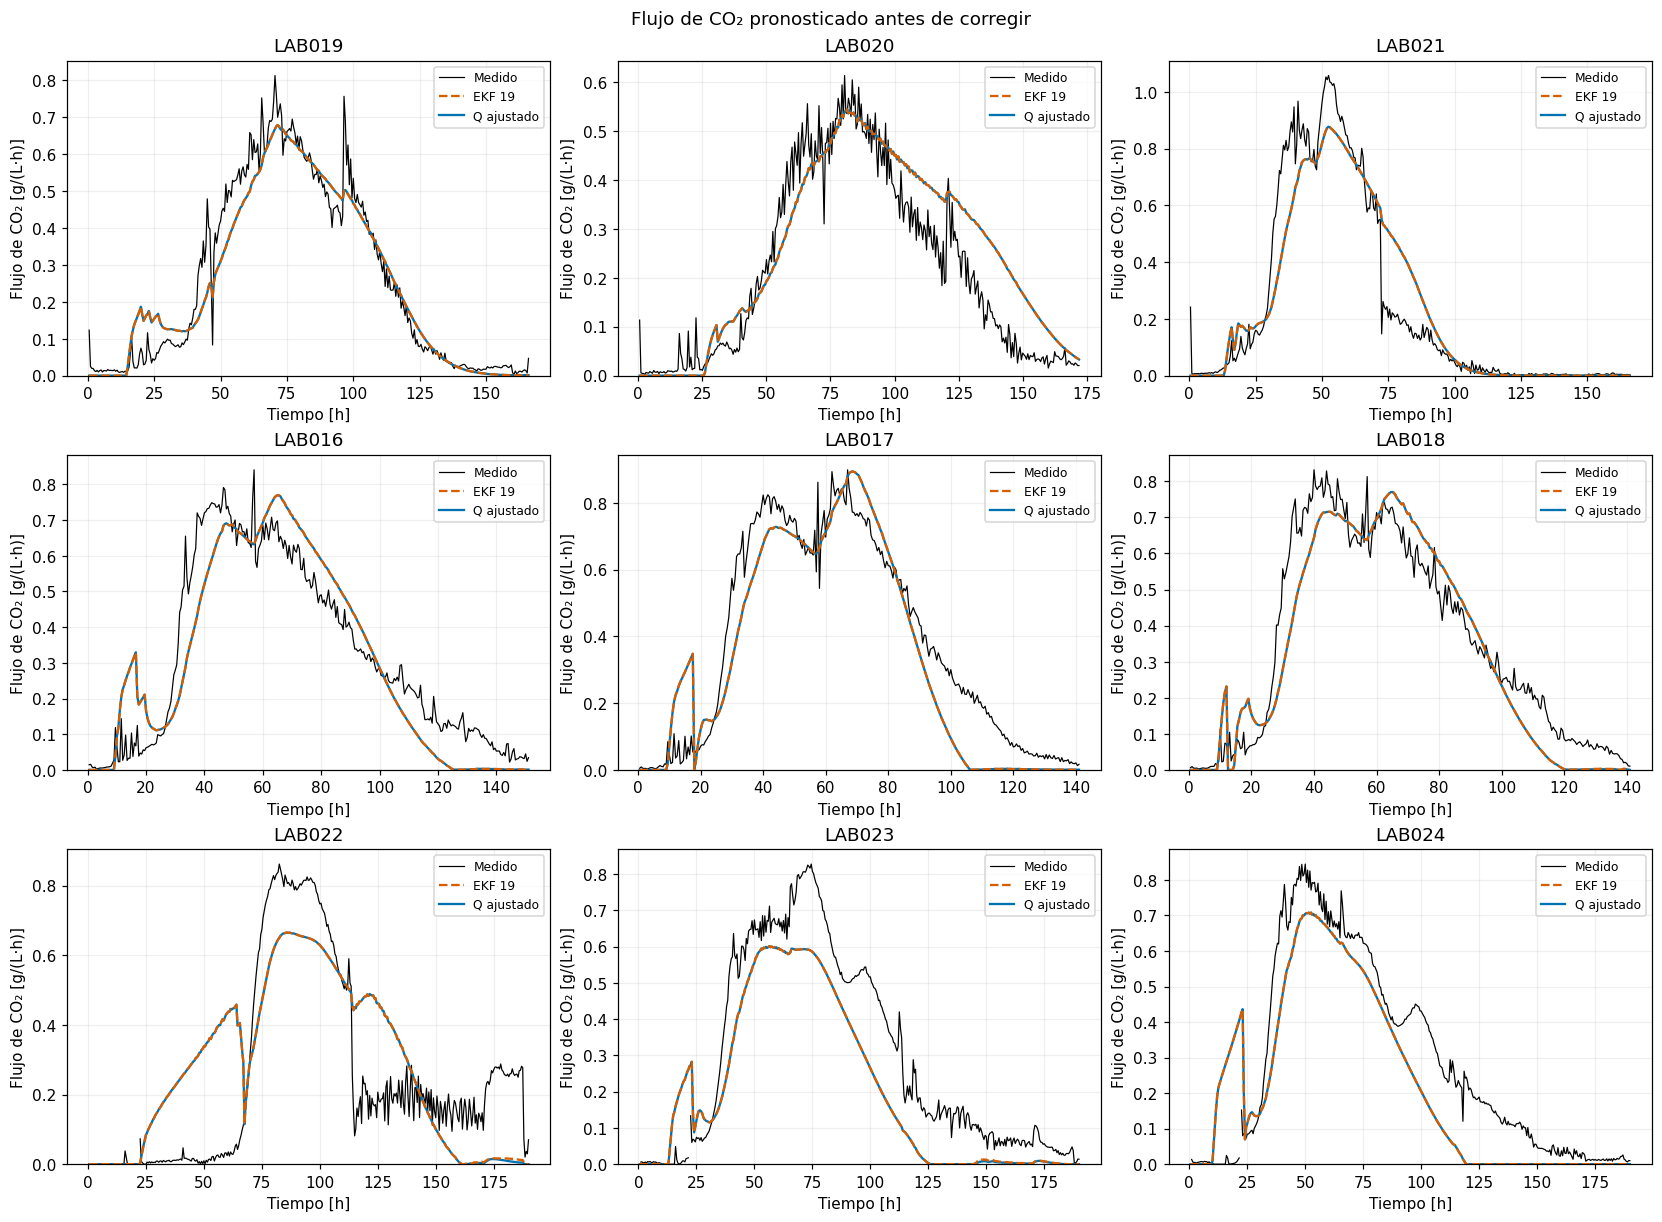

,LAB,ajuste,n,RMSE,sesgo,NIS_mediano,recortes
0,LAB019,EKF 19,217,0.0705,-0.0182,0.3514,39
1,LAB019,Q ajustado,217,0.0705,-0.0182,0.3515,19
2,LAB020,EKF 19,223,0.0865,0.0341,0.9451,8
3,LAB020,Q ajustado,223,0.0865,0.0341,0.9452,1
4,LAB021,EKF 19,166,0.1579,0.0025,1.5369,25
5,LAB021,Q ajustado,166,0.1579,0.0025,1.5369,41
6,LAB016,EKF 19,249,0.1067,-0.0273,1.8589,102
7,LAB016,Q ajustado,249,0.1067,-0.0273,1.8592,69
8,LAB017,EKF 19,213,0.1198,-0.0667,1.7891,136
9,LAB017,Q ajustado,213,0.1199,-0.0667,1.7711,75


In [8]:
gas_metrics=[]
fig,axes=plt.subplots(3,3,figsize=(15,11),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    sensor=data[lab]['sensor']
    ax.plot(sensor.index,sensor.measured,c='black',lw=.8,label='Medido')
    for label in labels:
        readings=results[label][lab][1]
        active=readings.loc[readings['update']]
        error=active.forecast-active.measured
        gas_metrics.append(dict(LAB=lab,ajuste=label,n=len(active),RMSE=np.sqrt(np.mean(error**2)),
                                sesgo=error.mean(),NIS_mediano=active.NIS.median(),
                                recortes=int(active.recortes.sum())))
        ax.plot(readings.t_h,readings.forecast,label=label,**styles[label])
    ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Flujo de CO₂ [g/(L·h)]',ylim=(0,None))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle('Flujo de CO₂ pronosticado antes de corregir')
plt.show()
gas_metrics=pd.DataFrame(gas_metrics)
assert gas_metrics.groupby('LAB').n.nunique().eq(1).all()
display(gas_metrics.round(4))


## YAN y azúcar total estimados

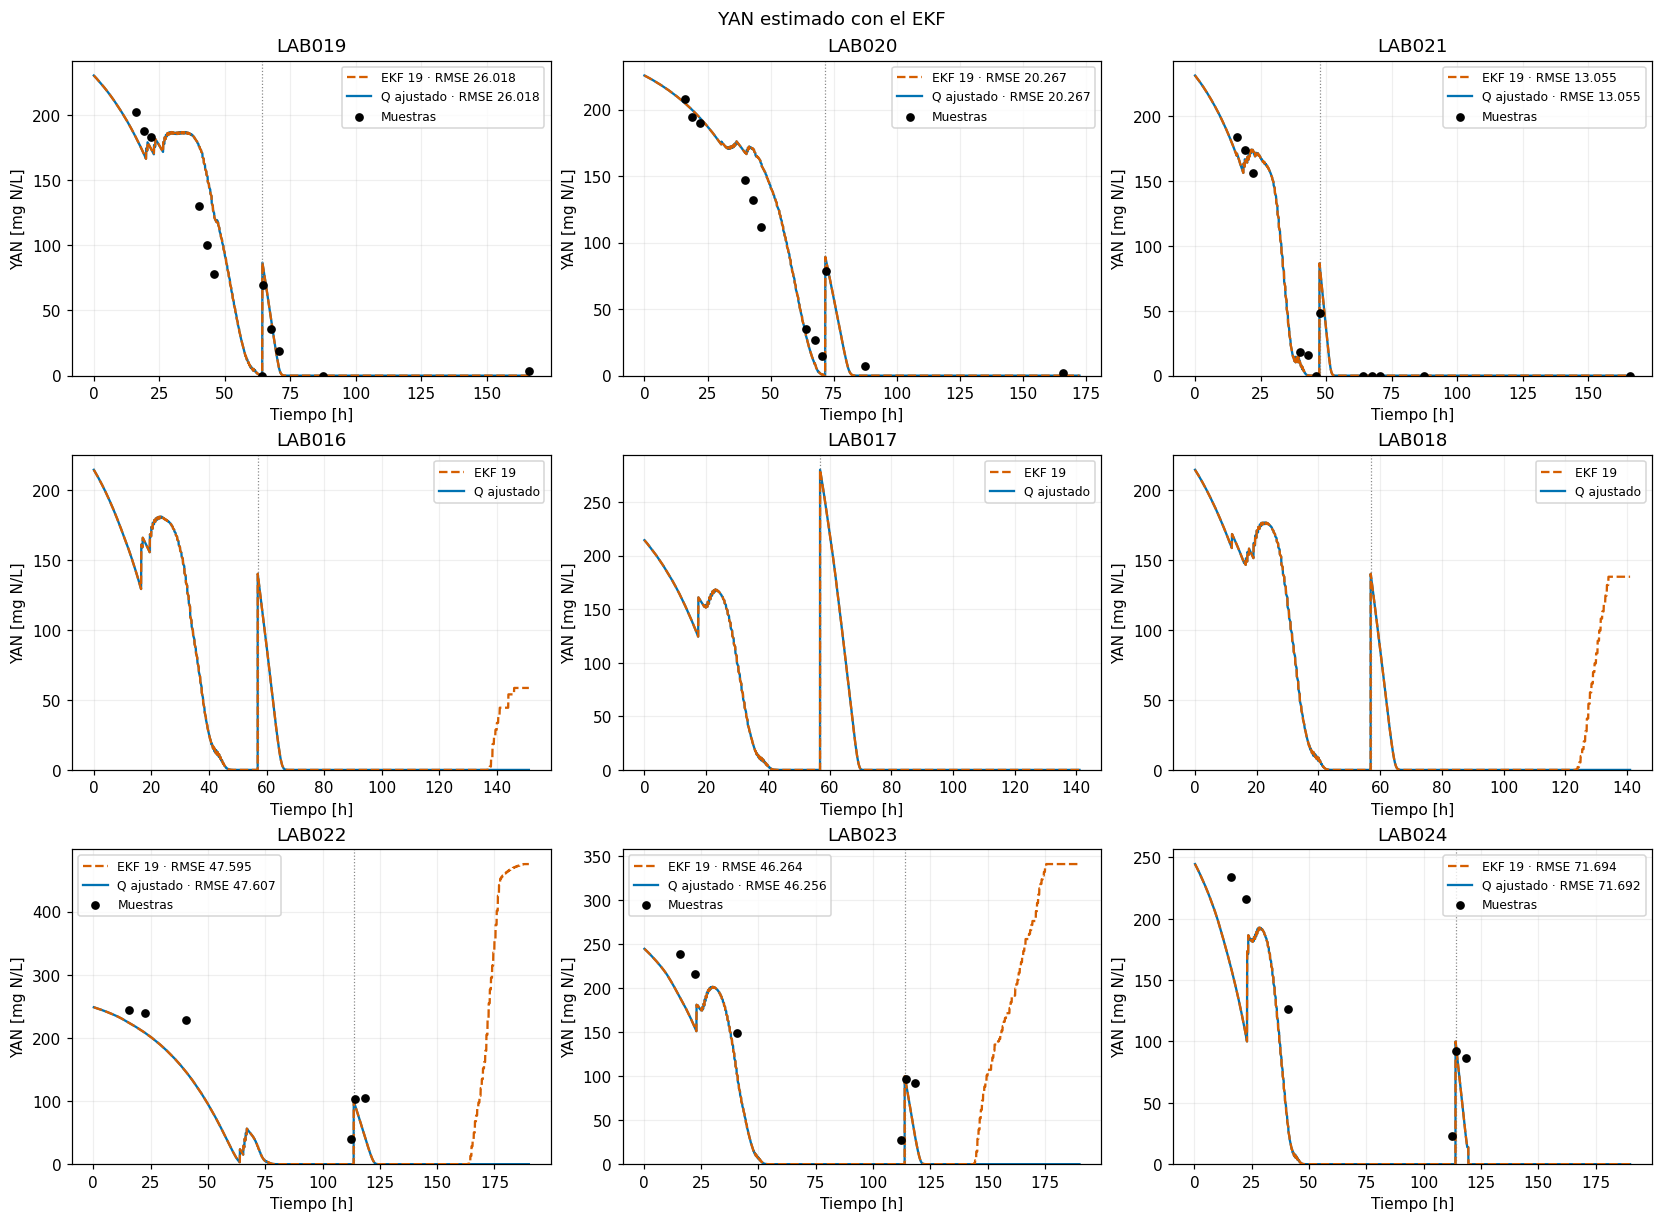

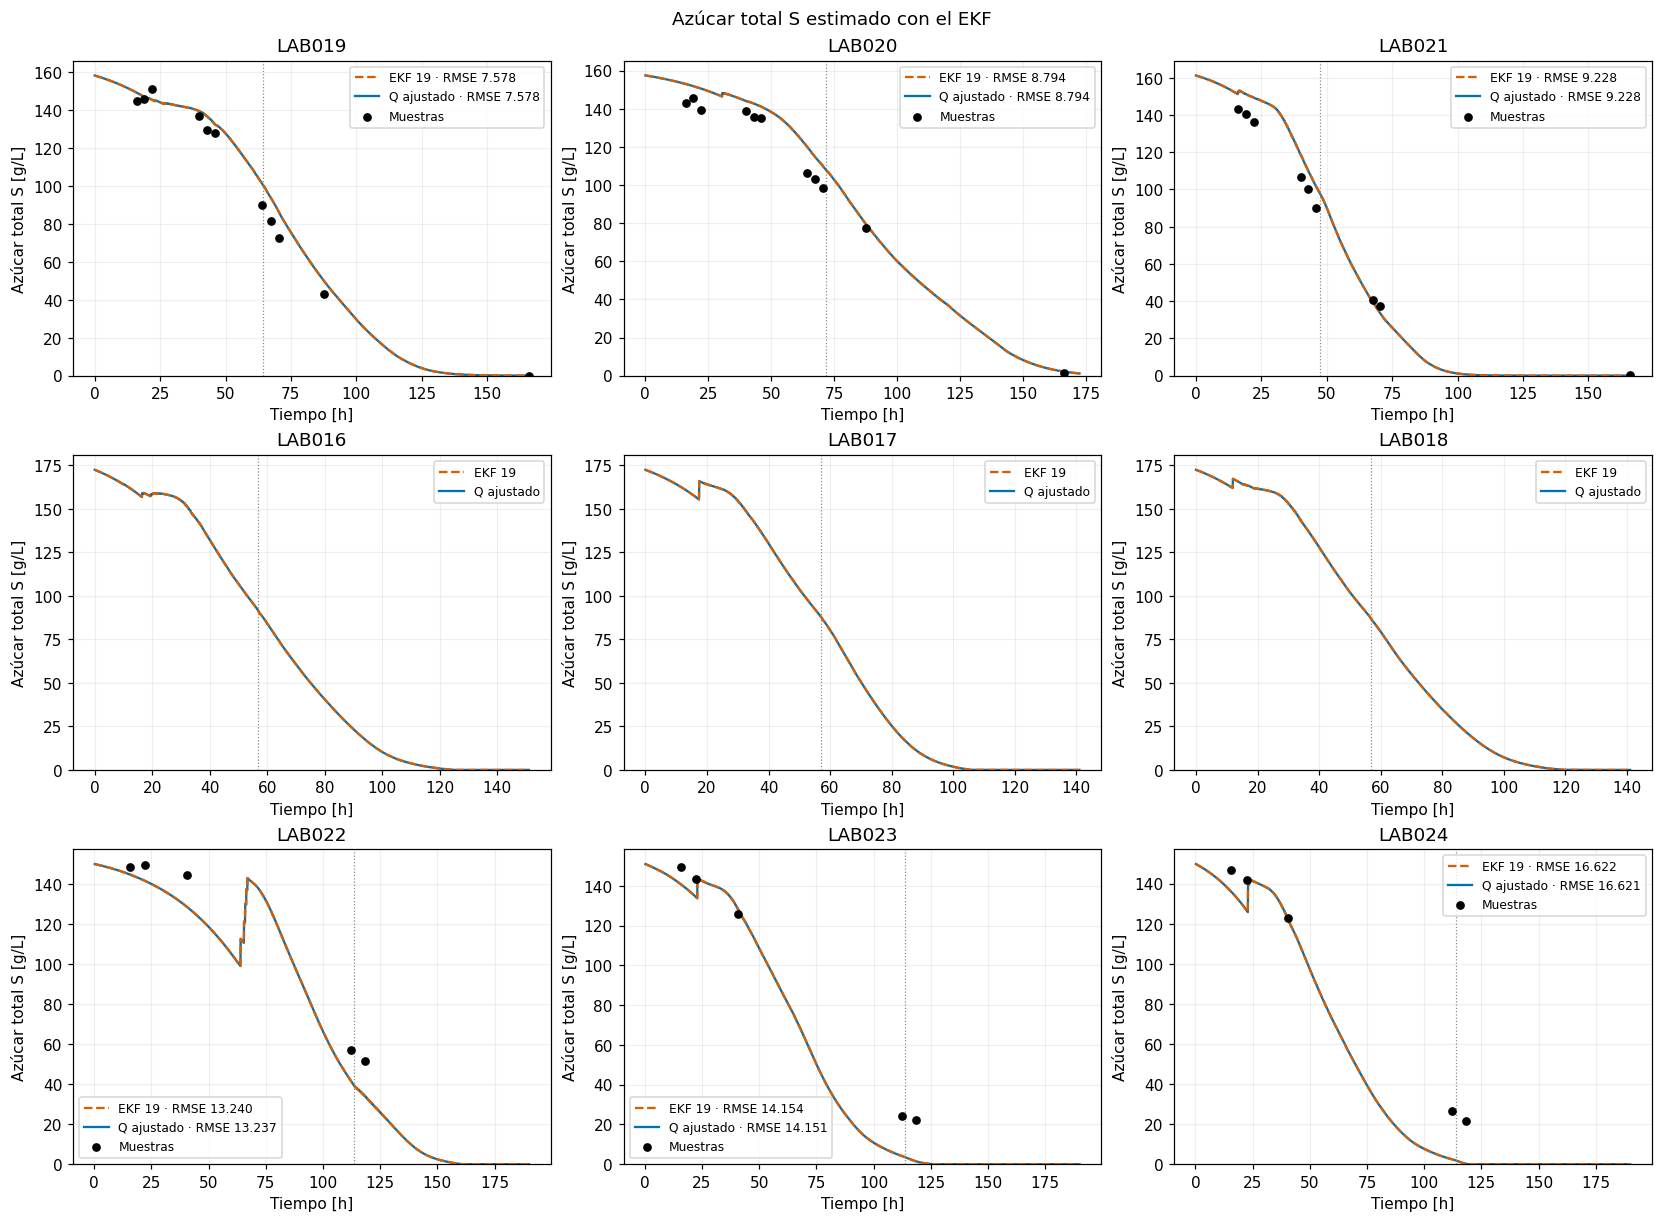

,LAB,Estado,Unidad,ajuste,n,RMSE,sesgo
0,LAB019,N,mg N/L,EKF 19,12,26.0178,8.8268
1,LAB019,N,mg N/L,Q ajustado,12,26.0179,8.8293
2,LAB020,N,mg N/L,EKF 19,12,20.2668,6.3252
3,LAB020,N,mg N/L,Q ajustado,12,20.2668,6.3256
4,LAB021,N,mg N/L,EKF 19,12,13.0552,0.8045
5,LAB021,N,mg N/L,Q ajustado,12,13.0548,0.8046
6,LAB022,N,mg N/L,EKF 19,6,47.5946,-40.9382
7,LAB022,N,mg N/L,Q ajustado,6,47.6069,-40.9483
8,LAB023,N,mg N/L,EKF 19,6,46.2637,-41.6075
9,LAB023,N,mg N/L,Q ajustado,6,46.2564,-41.6013


In [9]:
chem_rows = []
for state, state_index, title, unit, factor, recent_column in (
    ("N", 1, "YAN", "mg N/L", 1000., "YAN for plot"),
    ("GF", 2, "Azúcar total S", "g/L", 1., "GLU-FRU-320"),
):
    fig, axes = plt.subplots(3, 3, figsize=(15, 11), layout="constrained")
    for ax, lab in zip(axes.flat, LABS):
        inputs = data[lab]
        grid = inputs["grid"]
        if lab in historical:
            samples = chemical_observations(v.chem, lab, state)
            times = samples.t_h.to_numpy()
            observed = samples[CHEMICAL_COLUMNS[state]].to_numpy() * factor
        else:
            samples = holdout_chemistry.loc[holdout_chemistry.lab.eq(lab) &
                                             holdout_chemistry["sample"].ne("01")].dropna(subset=[recent_column])
            times = samples.hours.to_numpy()
            observed = samples[recent_column].to_numpy()
        valid = (times > grid[0]) & (times <= grid[-1])
        times, observed = times[valid], observed[valid]
        for label in labels:
            states = results[label][lab][0]
            legend_label = label
            if len(times):
                predicted = states_at_samples(inputs, models[label], states, times, state_index)[:, 0] * factor
                error = predicted - observed
                score = np.sqrt(np.mean(error**2))
                chem_rows.append(dict(LAB=lab, Estado=state, Unidad=unit, ajuste=label, n=len(error),
                                      RMSE=score, sesgo=error.mean()))
                legend_label += f" · RMSE {score:.3f}"
            ax.plot(grid, states[:, 0, state_index] * SCALE_EKF[state_index] * factor,
                    label=legend_label, **styles[label])
        if len(times):
            ax.scatter(times, observed, c="black", s=22, zorder=4, label="Muestras")
        for pulse in inputs["pulses"]:
            ax.axvline(pulse, c="#888888", ls=":", lw=.8)
        ax.set(title=lab, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", ylim=(0, None))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(f"{title} estimado con el EKF")
    plt.show()
chem_metrics = pd.DataFrame(chem_rows)
assert chem_metrics.groupby(["LAB", "Estado"]).n.nunique().eq(1).all()
display(chem_metrics.round(4))
